# CLAHE preprocessing — visual example

This notebook picks **5 random images** from the dataset, applies the same CLAHE preprocessing used by
`src/preprocess/clahe_preprocess.py`, and compares the original and processed versions.

**How the preprocessing works:** the image is converted to CIELAB and CLAHE is applied only to the
lightness channel **L**. The colour channels (a, b) are not changed, so the hue of fire and smoke is kept.

**What is compared**
1. Original vs CLAHE image, and a map of where lightness changed.
2. Histogram and cumulative distribution (CDF) of lightness, and histogram of saturation.
3. Image quality metrics before and after: brightness, contrast, dynamic range, entropy, sharpness,
   edge density, colourfulness and saturation, plus PSNR and SSIM between both versions.
4. Effect of the `clip_limit` parameter on one image.

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Locate the project root (the folder that contains `data/`), wherever the notebook is run from
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "src" / "preprocess"))
from clahe_preprocess import IMAGE_EXTS, apply_clahe, load_config  # noqa: E402

pd.set_option("display.float_format", "{:.2f}".format)

## 1. Configuration

In [2]:
# Same config file as the script: change the parameters there (or override them below to experiment)
cfg = load_config()
DATA_ROOT = cfg["data_root"]
SPLITS = cfg["splits"]
LABELS_DIR = PROJECT_ROOT / "data" / "classification_labels"

N_SAMPLES = 5
SEED = 42          # set to None for a different sample each run

clip_limit, tile_grid = cfg["clahe"]["clip_limit"], cfg["clahe"]["tile_grid"]

# Colours: fixed per version, used the same way in every chart
COLORS = {"original": "#2a78d6", "clahe": "#eb6834"}
TEXT, MUTED, GRID = "#1f1f1c", "#6b6b66", "#e4e4df"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": TEXT,
    "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
print(f"CLAHE  clip_limit={clip_limit}  tile_grid={tile_grid}x{tile_grid}")

CLAHE  clip_limit=2.0  tile_grid=8x8


## 2. Pick random images

If the classification CSVs from `prepare_labels.py` exist, they are used so each image also shows its class
(`no_fire`, `smoke`, `fire`). Otherwise the images are listed straight from the dataset folders.

In [3]:
csvs = [LABELS_DIR / f"{s}.csv" for s in SPLITS]
if all(p.is_file() for p in csvs):
    pool = pd.concat([pd.read_csv(p).assign(split=s) for s, p in zip(SPLITS, csvs)], ignore_index=True)
    pool["path"] = pool["image_path"].map(lambda p: PROJECT_ROOT / p)
else:
    pool = pd.DataFrame([{"split": s, "image": p.name, "path": p, "label_name": "?"}
                         for s in SPLITS for p in sorted((DATA_ROOT / s / "images").glob("*"))
                         if p.suffix.lower() in IMAGE_EXTS])

sample = pool.sample(N_SAMPLES, random_state=SEED).reset_index(drop=True)
display(sample[["split", "image", "label_name"]])

,split,image,label_name
0,train,AoF00506.jpg,no_fire
1,train,AoF04292.jpg,fire
2,val,AoF05259.jpg,smoke
3,test,WEB10872.jpg,fire
4,train,AoF05305.jpg,smoke


## 3. Helper functions

All metrics are computed on the image as it would be stored, in 8-bit RGB.

| Metric | What it measures | Expected effect of CLAHE |
|---|---|---|
| `mean_L` | average lightness (0–255) | small change |
| `rms_contrast` | standard deviation of lightness (global contrast) | goes up |
| `dynamic_range` | lightness range between the 1st and 99th percentile | goes up |
| `entropy` | information in the lightness histogram (bits, max 8) | goes up (flatter histogram) |
| `sharpness` | variance of the Laplacian (amount of fine detail) | goes up |
| `edge_density` | % of pixels marked as edges by Canny | goes up |
| `colorfulness` | Hasler & Süsstrunk colourfulness index | small change |
| `mean_saturation` | average HSV saturation (0–255) | small change |
| `psnr` / `ssim` | how similar the CLAHE image is to the original | high = gentle change |

In [4]:
def load_rgb(path):
    return cv2.cvtColor(cv2.imread(str(path), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


def clahe_rgb(img_rgb, clip=None, tile=None):
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    out = apply_clahe(bgr, clip or clip_limit, tile or tile_grid)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)


def lightness(img_rgb):
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)[..., 0]


def saturation(img_rgb):
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)[..., 1]


def hist256(channel):
    return np.bincount(channel.ravel(), minlength=256) / channel.size


def entropy(channel):
    p = hist256(channel)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def colorfulness(img_rgb):
    r, g, b = [c.astype(np.float64) for c in cv2.split(img_rgb)]
    rg, yb = r - g, 0.5 * (r + g) - b
    return float(np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()))


def ssim(a, b):
    # Standard SSIM (Wang et al. 2004) with an 11x11 Gaussian window, on 8-bit single-channel images
    a, b = a.astype(np.float64), b.astype(np.float64)
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    blur = lambda x: cv2.GaussianBlur(x, (11, 11), 1.5)
    mu_a, mu_b = blur(a), blur(b)
    var_a = blur(a * a) - mu_a ** 2
    var_b = blur(b * b) - mu_b ** 2
    cov = blur(a * b) - mu_a * mu_b
    s = ((2 * mu_a * mu_b + c1) * (2 * cov + c2)) / ((mu_a ** 2 + mu_b ** 2 + c1) * (var_a + var_b + c2))
    return float(s.mean())


def image_metrics(img_rgb):
    L = lightness(img_rgb)
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    p1, p99 = np.percentile(L, [1, 99])
    return {
        "mean_L": float(L.mean()),
        "rms_contrast": float(L.std()),
        "dynamic_range": float(p99 - p1),
        "entropy": entropy(L),
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        "edge_density": float((cv2.Canny(gray, 100, 200) > 0).mean() * 100),
        "colorfulness": colorfulness(img_rgb),
        "mean_saturation": float(saturation(img_rgb).mean()),
    }


def pair_metrics(orig_rgb, proc_rgb):
    return {
        "psnr": float(cv2.PSNR(orig_rgb, proc_rgb)),
        "ssim": ssim(lightness(orig_rgb), lightness(proc_rgb)),
    }

## 4. Original vs CLAHE

For each image:
- **Top row:** original, CLAHE, and a heatmap of how much the lightness changed (|ΔL|).
- **Bottom row:** lightness histogram, lightness CDF, and saturation histogram.
  A CLAHE CDF closer to a straight diagonal means the tones are spread more evenly.

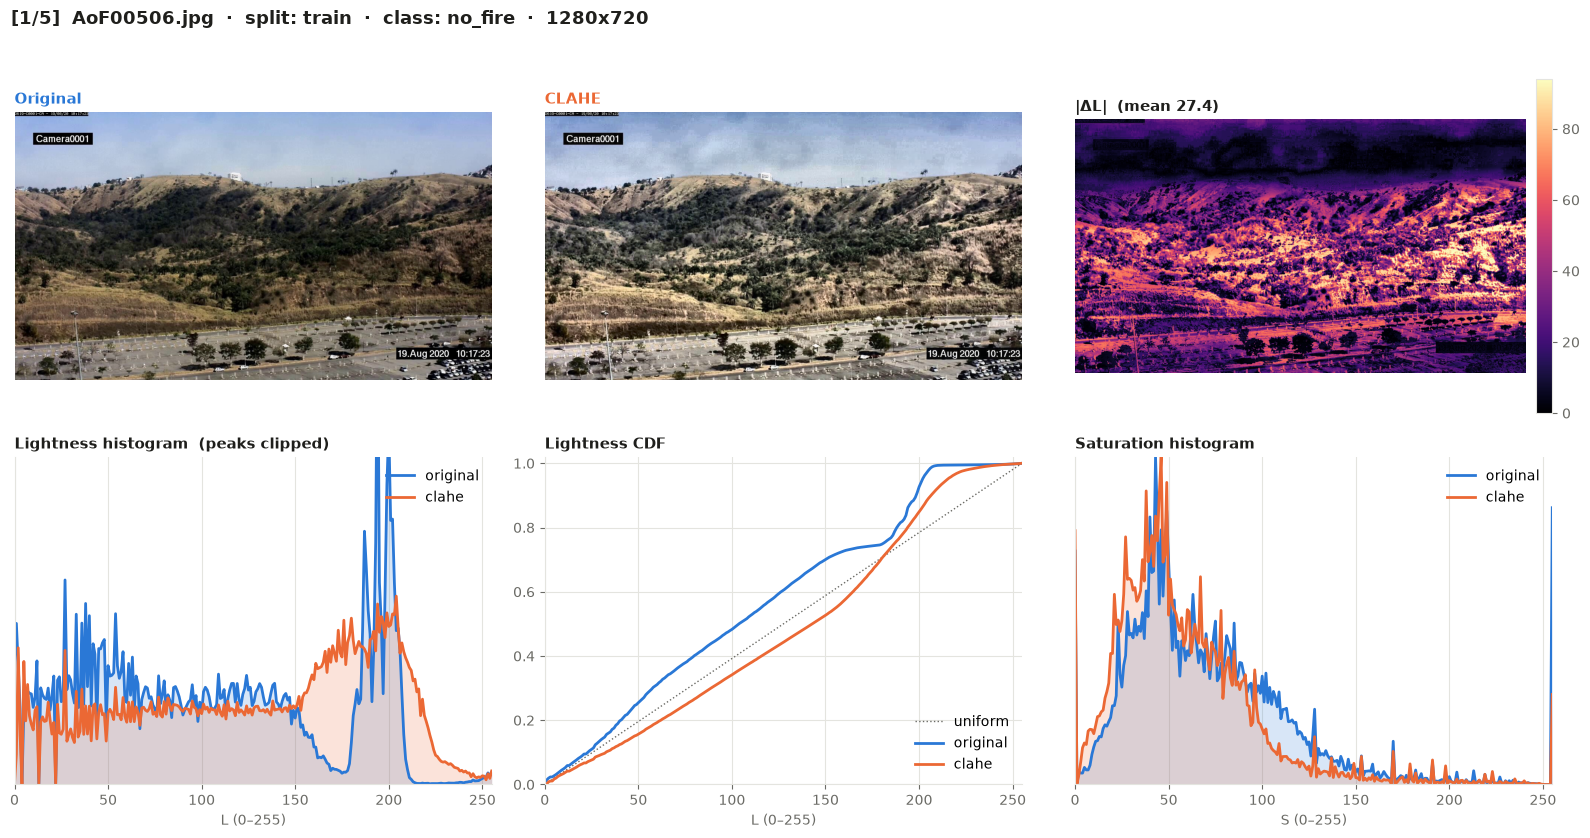

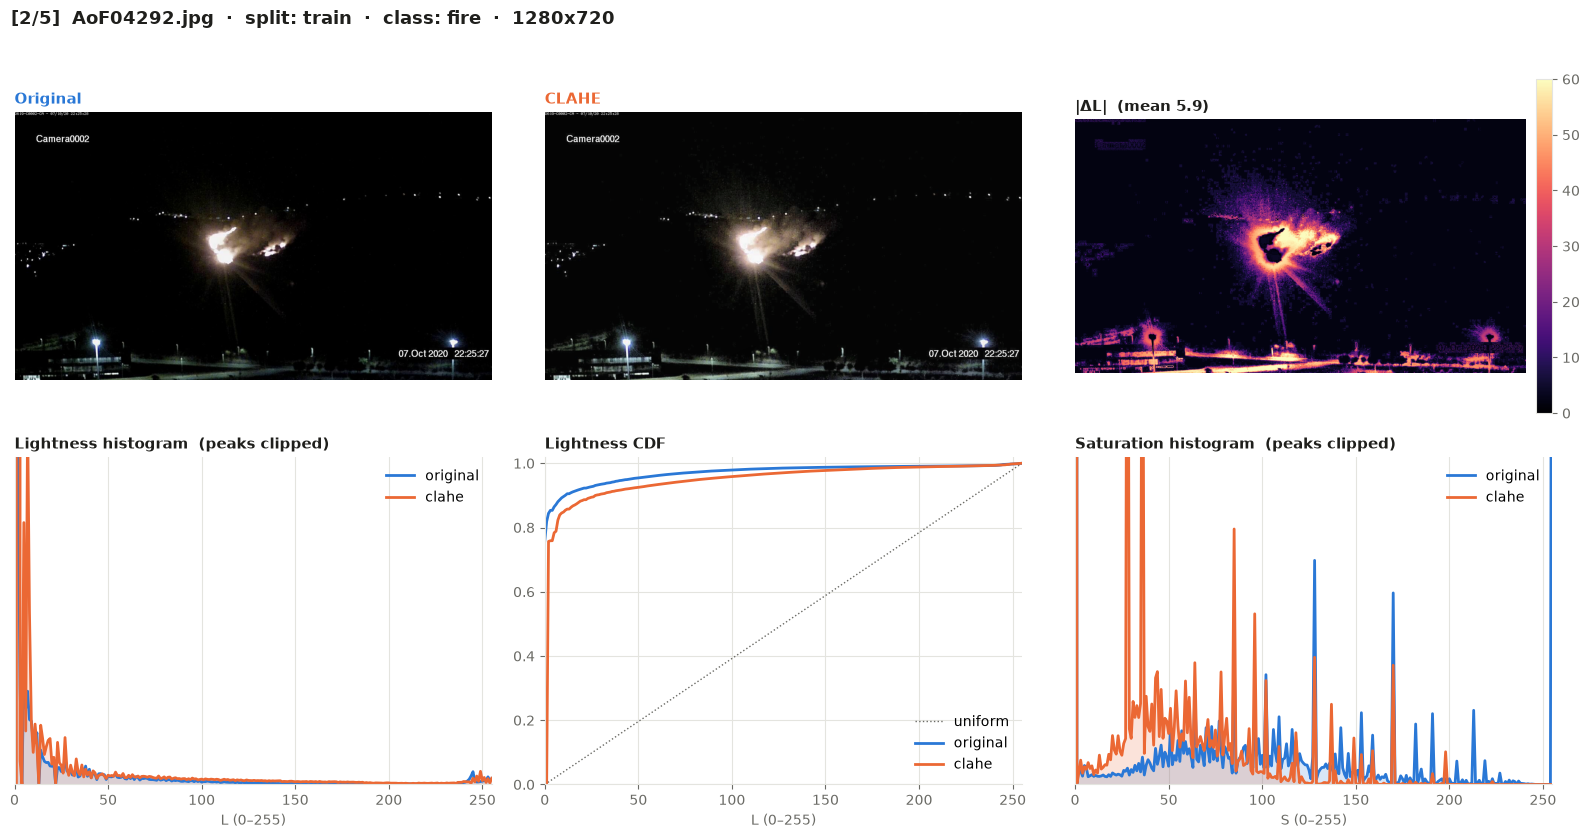

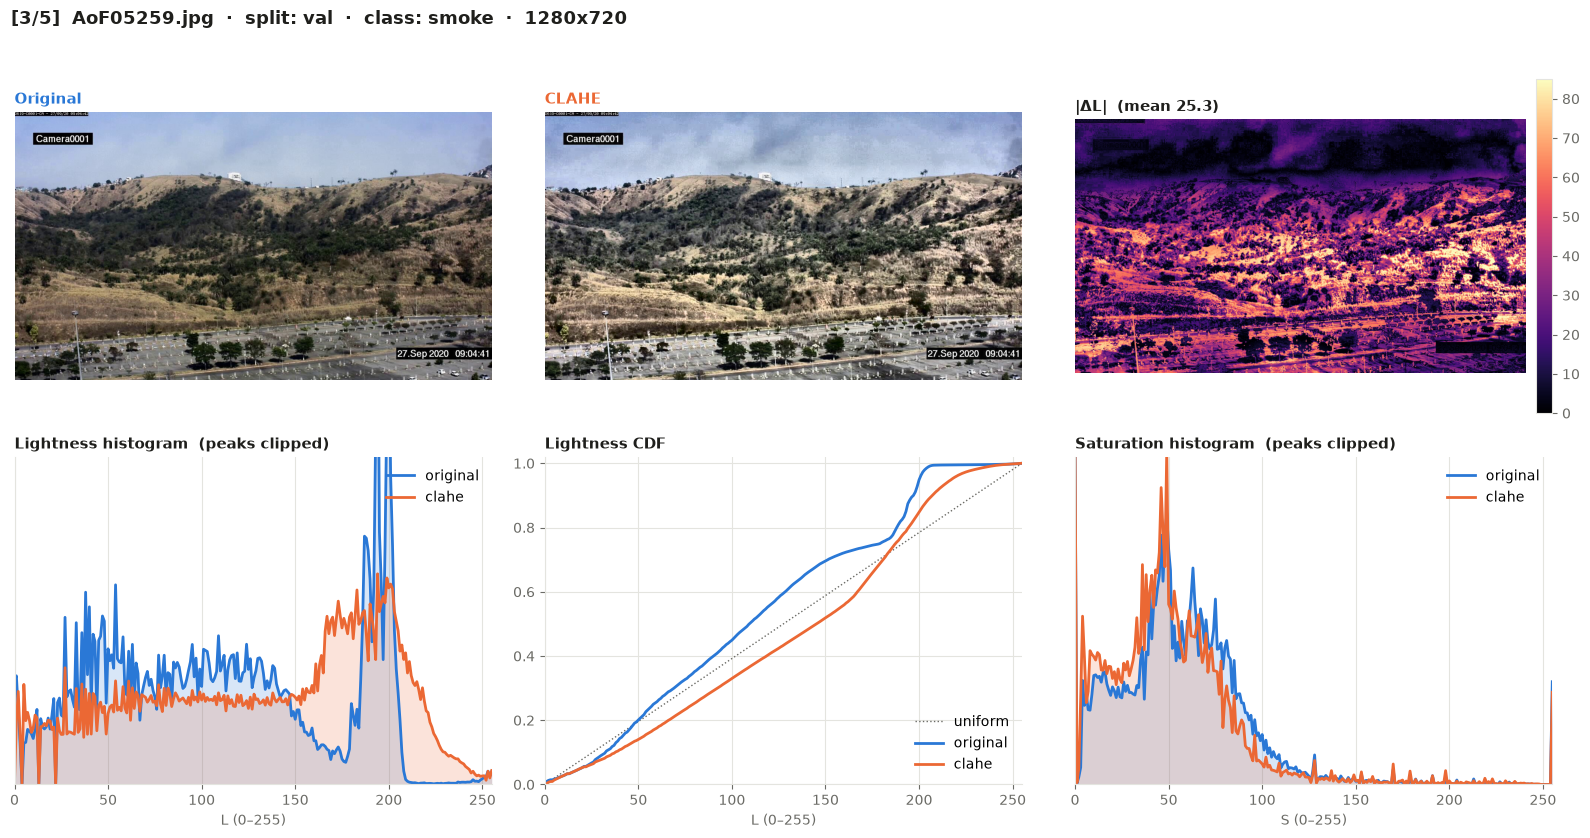

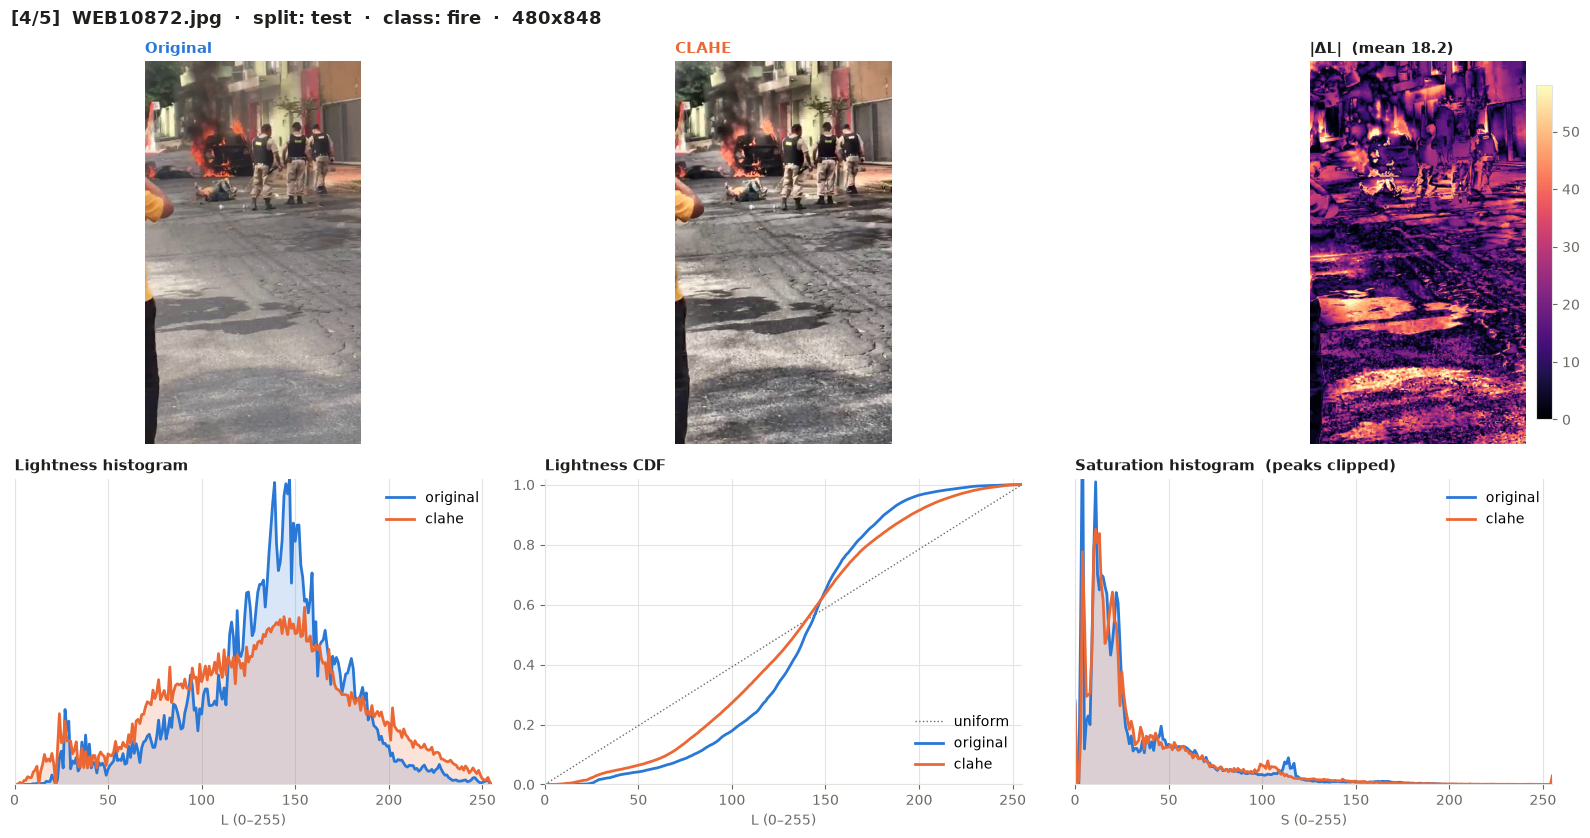

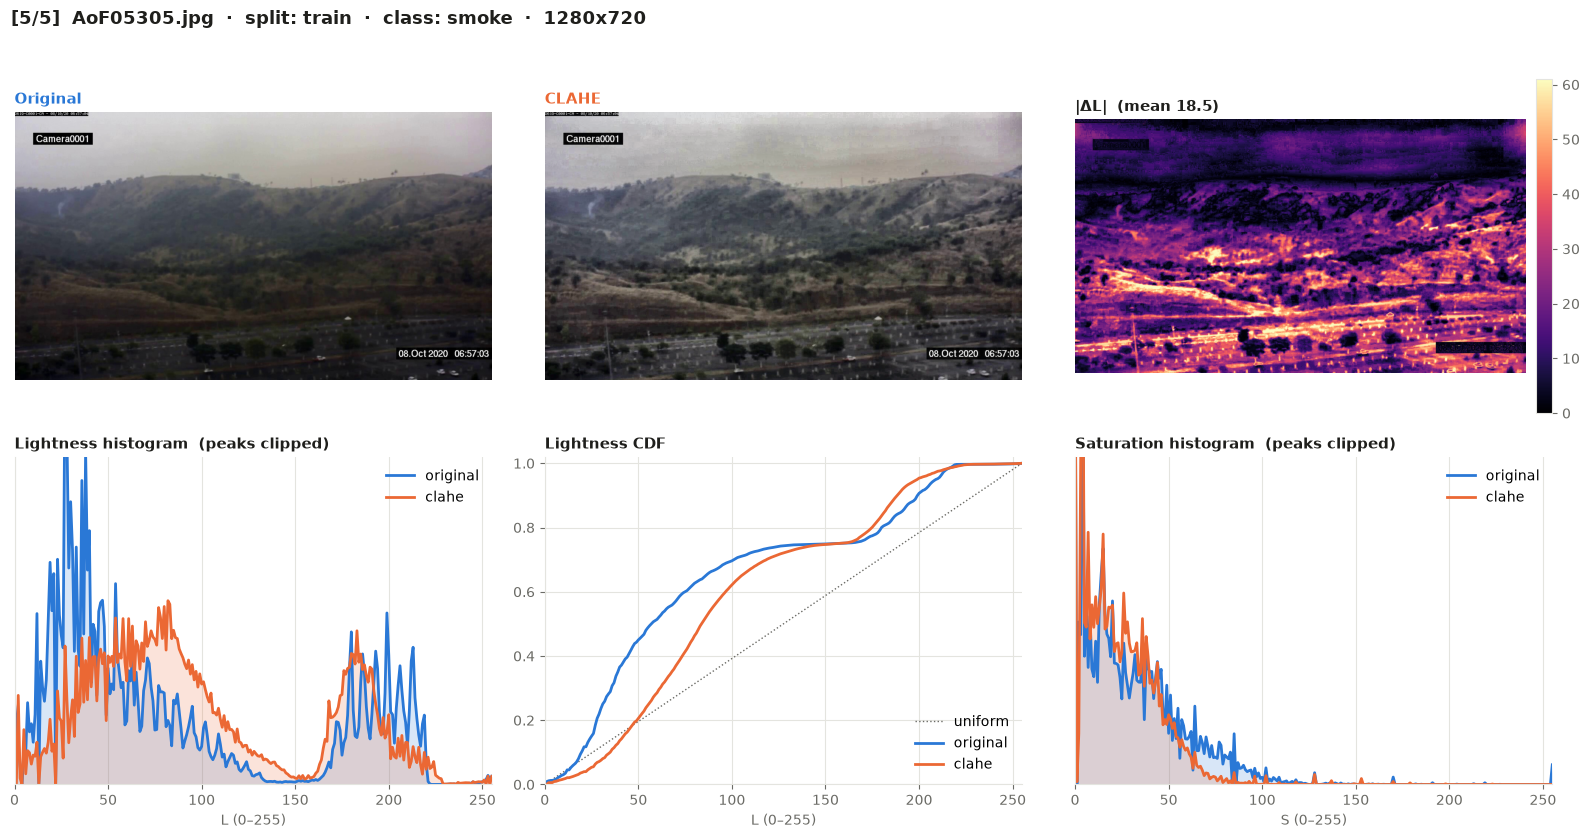

In [5]:
def plot_hist(ax, values_by_version, title, xlabel):
    x = np.arange(256)
    hists = {version: hist256(values) for version, values in values_by_version.items()}
    for version, h in hists.items():
        ax.fill_between(x, h, color=COLORS[version], alpha=0.18, linewidth=0)
        ax.plot(x, h, color=COLORS[version], linewidth=2, label=version)
    # Dark / saturated images have a huge spike at 0 or 255: clip it so the rest of the histogram is visible
    all_bins = np.concatenate(list(hists.values()))
    top = min(all_bins.max(), np.quantile(all_bins, 0.99) * 1.3)
    if top < all_bins.max():
        title += "  (peaks clipped)"
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, 255)
    ax.set_ylim(0, top)
    ax.set_yticks([])
    ax.legend(loc="upper right")


def plot_cdf(ax, values_by_version):
    x = np.arange(256)
    ax.plot(x, x / 255, color=MUTED, linewidth=1, linestyle=":", label="uniform")
    for version, values in values_by_version.items():
        ax.plot(x, np.cumsum(hist256(values)), color=COLORS[version], linewidth=2, label=version)
    ax.set_title("Lightness CDF", loc="left")
    ax.set_xlabel("L (0–255)")
    ax.set_xlim(0, 255)
    ax.set_ylim(0, 1.02)
    ax.legend(loc="lower right")


rows = []
for i, r in sample.iterrows():
    orig = load_rgb(r["path"])
    proc = clahe_rgb(orig)
    L_o, L_p = lightness(orig), lightness(proc)

    fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), gridspec_kw={"height_ratios": [1.25, 1]})
    fig.suptitle(f"[{i + 1}/{N_SAMPLES}]  {r['image']}  ·  split: {r['split']}  ·  class: {r['label_name']}  ·  "
                 f"{orig.shape[1]}x{orig.shape[0]}", x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXT)

    for ax, img, title in [(axes[0, 0], orig, "Original"), (axes[0, 1], proc, "CLAHE")]:
        ax.imshow(img)
        ax.set_title(title, loc="left", color=COLORS[title.lower()])
        ax.axis("off")

    diff = np.abs(L_p.astype(np.int16) - L_o.astype(np.int16))
    im = axes[0, 2].imshow(diff, cmap="magma", vmin=0, vmax=max(int(np.percentile(diff, 99.5)), 1))
    axes[0, 2].set_title(f"|ΔL|  (mean {diff.mean():.1f})", loc="left")
    axes[0, 2].axis("off")
    fig.colorbar(im, ax=axes[0, 2], fraction=0.035, pad=0.02)

    plot_hist(axes[1, 0], {"original": L_o, "clahe": L_p}, "Lightness histogram", "L (0–255)")
    plot_cdf(axes[1, 1], {"original": L_o, "clahe": L_p})
    plot_hist(axes[1, 2], {"original": saturation(orig), "clahe": saturation(proc)},
              "Saturation histogram", "S (0–255)")

    fig.tight_layout()
    plt.show()

    pair = pair_metrics(orig, proc)
    for version, img in [("original", orig), ("clahe", proc)]:
        rows.append({"n": i + 1, "image": r["image"], "class": r["label_name"], "version": version,
                     **image_metrics(img), **(pair if version == "clahe" else {})})

metrics_df = pd.DataFrame(rows)

## 5. Metrics comparison

### 5.1 Before and after, per image

In [6]:
METRICS = ["mean_L", "rms_contrast", "dynamic_range", "entropy", "sharpness",
           "edge_density", "colorfulness", "mean_saturation"]

wide = metrics_df.pivot_table(index=["n", "image", "class"], columns="version", values=METRICS, sort=False)
wide = wide.reindex(columns=pd.MultiIndex.from_product([METRICS, ["original", "clahe"]]))
display(wide)

print("Similarity between original and CLAHE (L channel for SSIM):")
display(metrics_df.loc[metrics_df["version"] == "clahe", ["n", "image", "class", "psnr", "ssim"]]
        .set_index("n"))

mean_L        rms_contrast       dynamic_range  \
                       original  clahe     original clahe      original   
n image        class                                                      
1 AoF00506.jpg no_fire   108.13 130.83        65.60 65.19        207.00   
2 AoF04292.jpg fire        7.51  13.41        29.77 36.56        188.00   
3 AoF05259.jpg smoke     112.93 133.23        61.53 64.12        204.00   
4 WEB10872.jpg fire      135.18 131.37        40.27 50.01        198.00   
5 AoF05305.jpg smoke      86.01 100.10        68.57 58.02        216.00   

                               entropy       sharpness         edge_density  \
                        clahe original clahe  original   clahe     original   
n image        class                                                          
1 AoF00506.jpg no_fire 233.00     7.53  7.79   1180.47 1750.63        10.05   
2 AoF04292.jpg fire    213.00     2.10  2.32    847.90  820.04         1.05   
3 AoF05259.jpg smoke   233.00     7.50  7.80   1176.34 1769.14        10.22   
4 WEB10872.jpg fire    220.00     7.27  7.64    150.89  464.96         4.05   
5 AoF05305.jpg smoke   214.00     7.23  7.47    827.34  809.90         0.46   

                             colorfulness       mean_saturation        
                       clahe     original clahe        original clahe  
n image        class                                                   
1 AoF00506.jpg no_fire 18.74        30.84 31.96           71.48 58.72  
2 AoF04292.jpg fire     1.75         6.64  7.09           23.02 13.03  
3 AoF05259.jpg smoke   18.72        28.72 29.29           57.16 51.40  
4 WEB10872.jpg fire    10.99        27.39 27.02           34.60 35.67  
5 AoF05305.jpg smoke    0.82         8.55  8.98           31.92 24.61

Similarity between original and CLAHE (L channel for SSIM):


,image,class,psnr,ssim
n,,,,
1,AoF00506.jpg,no_fire,17.18,0.83
2,AoF04292.jpg,fire,26.58,0.62
3,AoF05259.jpg,smoke,17.67,0.85
4,WEB10872.jpg,fire,21.07,0.85
5,AoF05305.jpg,smoke,21.85,0.84


### 5.2 Relative change

Change of each metric after CLAHE, in % of the original value. Each dot is one image and the bar is the mean
over the 5 images.

,original_mean,clahe_mean,change_%_mean,change_%_min,change_%_max
mean_L,89.95,101.79,26.22,-2.82,78.56
rms_contrast,53.15,54.78,7.04,-15.39,24.18
dynamic_range,202.60,222.60,10.05,-0.93,14.22
entropy,6.33,6.60,5.25,3.30,10.52
sharpness,836.59,1122.93,60.29,-3.29,208.15
edge_density,5.17,10.20,97.26,66.32,171.35
colorfulness,20.43,20.87,3.25,-1.33,6.87
mean_saturation,43.63,36.68,-18.23,-43.38,3.09


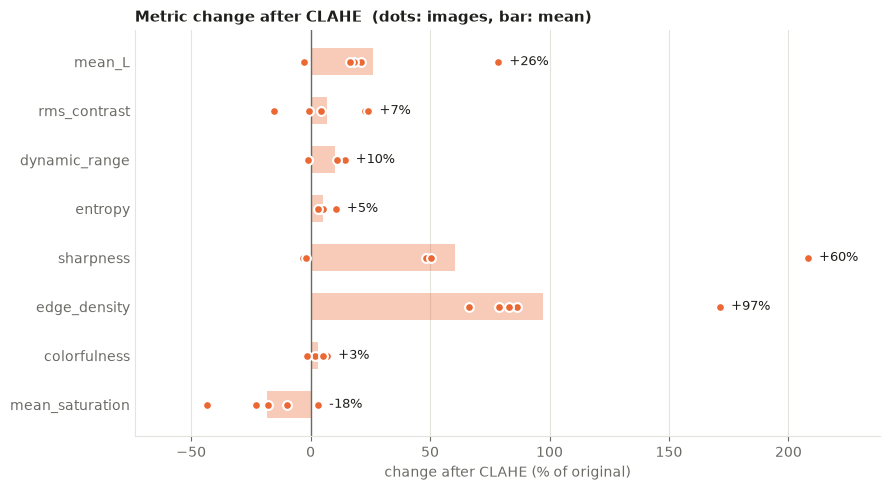

In [7]:
orig_m = metrics_df[metrics_df["version"] == "original"].set_index("n")[METRICS]
proc_m = metrics_df[metrics_df["version"] == "clahe"].set_index("n")[METRICS]
change = (proc_m - orig_m) / orig_m.replace(0, np.nan) * 100

summary = pd.DataFrame({"original_mean": orig_m.mean(), "clahe_mean": proc_m.mean(),
                        "change_%_mean": change.mean(), "change_%_min": change.min(),
                        "change_%_max": change.max()})
display(summary)

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(METRICS))[::-1]
ax.barh(y, change.mean().values, height=0.55, color=COLORS["clahe"], alpha=0.35, linewidth=0)
for k, metric in enumerate(METRICS):
    ax.scatter(change[metric], np.full(len(change), y[k]), s=40, color=COLORS["clahe"],
               edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"{change[metric].mean():+.0f}%", (max(change[metric].max(), change[metric].mean(), 0), y[k]),
                xytext=(8, 0), textcoords="offset points", va="center", color=TEXT, fontsize=9)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, METRICS)
ax.set_xlabel("change after CLAHE (% of original)")
ax.set_title("Metric change after CLAHE  (dots: images, bar: mean)", loc="left")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.margins(x=0.12)
plt.tight_layout()
plt.show()

## 6. Effect of `clip_limit`

`clip_limit` controls how much the contrast can be amplified in each tile. Low values give a gentle effect;
high values give stronger contrast but also amplify noise and JPEG artefacts (especially in smooth areas like
sky and smoke). Shown on the first sampled image.

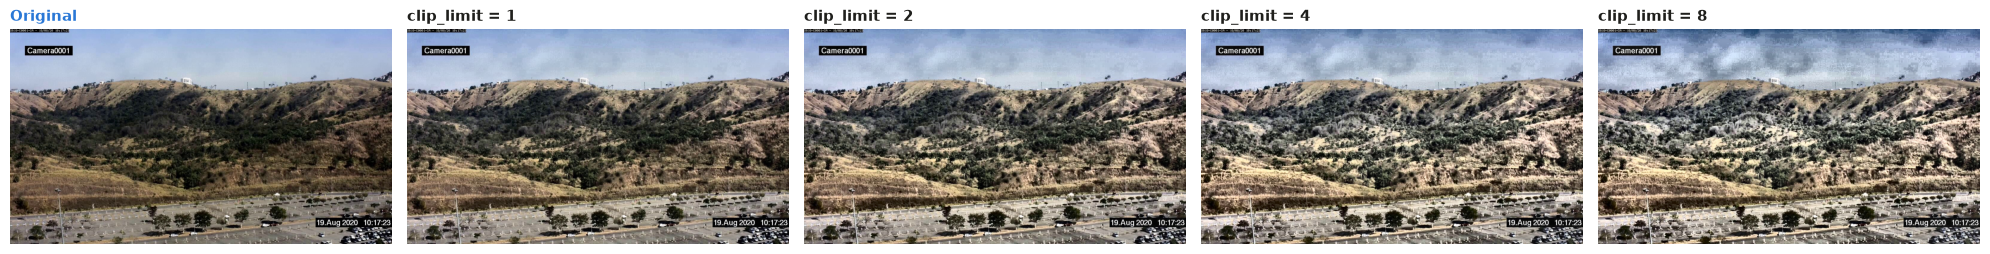

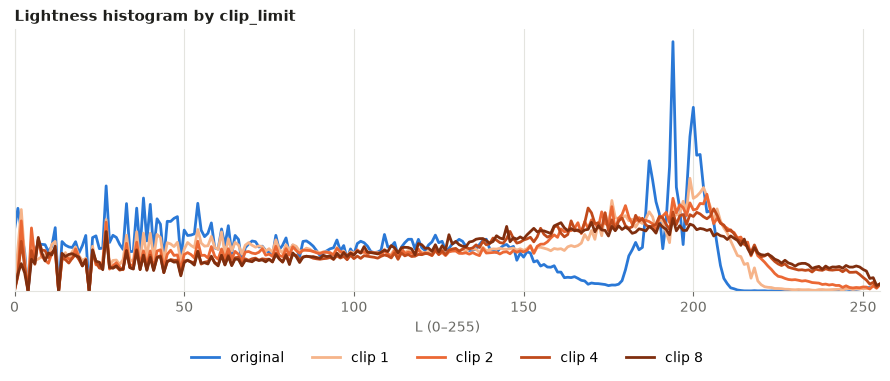

,original,clip 1,clip 2,clip 4,clip 8
mean_L,108.13,122.30,130.83,137.57,136.78
rms_contrast,65.60,64.65,65.19,65.83,65.63
dynamic_range,207.00,217.00,233.00,242.00,243.00
entropy,7.53,7.73,7.79,7.85,7.89
sharpness,1180.47,1412.11,1750.63,2205.41,2420.12
edge_density,10.05,15.46,18.74,20.27,20.99
colorfulness,30.84,31.56,31.96,32.01,31.88
mean_saturation,71.48,61.91,58.72,56.91,57.70
psnr,NaN,22.02,17.18,14.14,13.23
ssim,NaN,0.94,0.83,0.73,0.66


In [8]:
CLIP_VALUES = [1.0, 2.0, 4.0, 8.0]
# Sequential ramp (one hue, light -> dark) for increasing clip_limit
RAMP = ["#f6b48a", "#eb6834", "#c04a1b", "#7f2e0e"]

orig = load_rgb(sample.loc[0, "path"])
versions = {c: clahe_rgb(orig, clip=c) for c in CLIP_VALUES}

fig, axes = plt.subplots(1, len(CLIP_VALUES) + 1, figsize=(20, 3.6))
axes[0].imshow(orig)
axes[0].set_title("Original", loc="left", color=COLORS["original"])
for ax, (c, img) in zip(axes[1:], versions.items()):
    ax.imshow(img)
    ax.set_title(f"clip_limit = {c:g}", loc="left")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(256)
ax.plot(x, hist256(lightness(orig)), color=COLORS["original"], linewidth=2, label="original")
for color, (c, img) in zip(RAMP, versions.items()):
    ax.plot(x, hist256(lightness(img)), color=color, linewidth=2, label=f"clip {c:g}")
ax.set_title("Lightness histogram by clip_limit", loc="left")
ax.set_xlabel("L (0–255)")
ax.set_xlim(0, 255)
ax.set_ylim(bottom=0)
ax.set_yticks([])
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout()
plt.show()

display(pd.DataFrame({f"clip {c:g}": {**image_metrics(img), **pair_metrics(orig, img)}
                      for c, img in versions.items()}).assign(original=pd.Series(image_metrics(orig)))
        [["original", *[f"clip {c:g}" for c in CLIP_VALUES]]])

## 7. How to read the results

- **Contrast, dynamic range and entropy go up:** the lightness histogram is spread over more of the 0–255 range,
  so dark and washed-out images show more detail.
- **Sharpness and edge density go up:** CLAHE strengthens local detail. This helps with smoke edges, but it also
  amplifies sensor noise and compression artefacts — check the |ΔL| map for noisy flat areas.
- **Colour metrics change little:** only L is modified, so hue is kept; colourfulness and saturation can still
  shift slightly because the RGB values are recomputed from the new lightness.
- **High SSIM / PSNR** means the change is gentle. If SSIM drops a lot, `clip_limit` is probably too high for
  this dataset.

To build the full preprocessed dataset:

```bash
python src/preprocess/clahe_preprocess.py
```

The parameters are read from `src/preprocess/clahe_config.json`.